# Step 6 — The N=5 gate

**The first real pass or fail.** Steps 1 to 3 built the agent, steps 4 and 5 built the
instruments and checked them against answers already known. Nothing so far has been
allowed to fail, because an instrument disagreeing with a known answer is a broken
instrument, not a result.

This step is different. The target is an exact answer the agent has never seen, and the
agent can miss it.

**Why N=5 rather than N=3.** At N=3 the exact equilibrium *is* `shoot_strongest`, so
reproducing it shows only that the agent found the obvious rule — step 5 measured exactly
that and said so. At N=5 the exact profile has a shape **no heuristic produces**, and the
targeting policy behind it has magnitudes no heuristic produces either. (Its U-shape alone is
shared with Archetti's rule restricted to the neighbours, which under ranked seating is "always
shoot left"; folder 04 step 3 measures that rule.)

**The order of business, which is not negotiable:**

1. State the target **before** training, so it cannot be fitted after the fact.
2. Classify the equilibrium from the stagnation rate **before** reading any survival number.
3. Check the **ordering** before the individual values.
4. Apply the gate across **five seeds**, because one seed is an anecdote.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

from gruel_env import GruelEnv, MISS, SHOOT_LEFT, N_ACTIONS

N_PLAYERS = 5
SEED = 0

torch.set_num_threads(1)

print("torch", torch.__version__)
print("players", N_PLAYERS)

torch 2.2.2
players 5


## The target, stated first

The exact survival probabilities at N=5 on a circle with accuracies ascending around it.
Computed by backward induction in folder 02, which plays no episodes at all — so these
are not estimates and carry no error bar.

In [2]:
EXACT = {0.4: 0.24959, 0.5: 0.21073, 0.6: 0.17970, 0.7: 0.16194, 0.8: 0.19804}
GATE_THRESHOLD = 0.95

print("accuracy    exact     95% of it")
for accuracy in sorted(EXACT):
    if accuracy == 0.7:
        note = "   <- the worst place to be"
    else:
        note = ""
    print("   %.1f      %.5f   %.5f%s"
          % (accuracy, EXACT[accuracy], GATE_THRESHOLD * EXACT[accuracy], note))

print()
print("sums to:", round(sum(EXACT.values()), 5))

accuracy    exact     95% of it
   0.4      0.24959   0.23711
   0.5      0.21073   0.20019
   0.6      0.17970   0.17071
   0.7      0.16194   0.15384   <- the worst place to be
   0.8      0.19804   0.18814

sums to: 1.0


**The shape is the point, and it is not monotone.** Read the column of exact values
downward: it falls, falls, falls, and then **rises again at the strongest player**. The
weakest does best, and the *second-strongest* does worst of anyone — worse than the
strongest it is trying to survive.

So there are two different things to check, and the second is the harder one:

In [3]:
descending = sorted(EXACT, key=EXACT.get, reverse=True)
worst_rank = min(EXACT, key=EXACT.get)

print("ranks ordered best-surviving first:", descending)
print("the worst place to be:            ", worst_rank)
print()
print("is the ordering simply 'weaker is better' all the way down?")
monotone = descending == sorted(EXACT, reverse=True)
print("   ", monotone)
print()
print("So a tidy monotone ordering is NOT the right answer. An agent that produces one")
print("has failed this step, however reasonable that ordering looks.")

ranks ordered best-surviving first: [0.4, 0.5, 0.8, 0.6, 0.7]
the worst place to be:             0.7

is the ordering simply 'weaker is better' all the way down?
    False

So a tidy monotone ordering is NOT the right answer. An agent that produces one
has failed this step, however reasonable that ordering looks.


**Why the seating must be ranked.** The profile above is computed for one specific
arrangement — accuracies ascending around the circle, so each player's neighbours are the
two nearest it in skill. Shuffle the seats and the game changes: the numbers above stop
being the right comparison. Step 7 changes exactly that dial and nothing else.

In [4]:
check_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating="ranked", seed=1000)
check_game.reset()
print("seating (position -> accuracy):", [round(float(a), 2) for a in check_game.accuracies])
print("ascending around the circle?  ",
      list(check_game.accuracies) == sorted(check_game.accuracies))

seating (position -> accuracy): [0.4, 0.5, 0.6, 0.7, 0.8]
ascending around the circle?   True


## The agent

Unchanged from step 3 apart from the player count. One shared network; an actor that
sees four numbers whatever $N$ is; a critic that sees the whole board plus a one-hot
saying whose value it is estimating.

In [5]:
OBSERVATION_SIZE = 4
HIDDEN_SIZE = 64


class SharedActorCritic(nn.Module):
    def __init__(self, n_players):
        super().__init__()
        self.n_players = n_players
        self.actor_first = nn.Linear(OBSERVATION_SIZE, HIDDEN_SIZE)
        self.actor_second = nn.Linear(HIDDEN_SIZE, N_ACTIONS)
        critic_input_size = 2 * n_players + n_players
        self.critic_first = nn.Linear(critic_input_size, HIDDEN_SIZE)
        self.critic_second = nn.Linear(HIDDEN_SIZE, 1)
        self.activation = nn.Tanh()

    def action_logits(self, observation):
        hidden = self.activation(self.actor_first(observation))
        return self.actor_second(hidden)

    def value(self, state, agent_one_hot):
        combined = torch.cat([state, agent_one_hot], dim=-1)
        hidden = self.activation(self.critic_first(combined))
        return self.critic_second(hidden).squeeze(-1)


def global_state(game):
    numbers = []
    for position in range(game.n):
        numbers.append(game.accuracies[position])
        if position in game.order:
            numbers.append(1.0)
        else:
            numbers.append(0.0)
    return np.array(numbers, dtype=np.float32)


def one_hot(position, n_players):
    vector = np.zeros(n_players, dtype=np.float32)
    vector[position] = 1.0
    return vector


model = SharedActorCritic(n_players=N_PLAYERS)
total = 0
for parameter in model.parameters():
    total = total + parameter.numel()
print("parameters:", total)
print("critic input width:", 2 * N_PLAYERS + N_PLAYERS, "(2N + N)")

parameters: 1604
critic input width: 15 (2N + N)


In [6]:
def collect_batch(model, game, episodes):
    observations = {p: [] for p in range(game.n)}
    actions = {p: [] for p in range(game.n)}
    old_log_probabilities = {p: [] for p in range(game.n)}
    values = {p: [] for p in range(game.n)}
    returns = {p: [] for p in range(game.n)}
    states = {p: [] for p in range(game.n)}
    agent_flags = {p: [] for p in range(game.n)}

    for _ in range(episodes):
        game.reset()
        episode_observations = {p: [] for p in range(game.n)}
        episode_actions = {p: [] for p in range(game.n)}
        episode_log_probabilities = {p: [] for p in range(game.n)}
        episode_values = {p: [] for p in range(game.n)}
        episode_states = {p: [] for p in range(game.n)}
        episode_flags = {p: [] for p in range(game.n)}

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()

            # A finished agent is handed to us one last time, so PettingZoo can retire
            # it. Stepping with None is how we say 'nothing to do here'.
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            observation_tensor = torch.from_numpy(observation)
            state_array = global_state(game)
            agent_array = one_hot(actor, game.n)

            with torch.no_grad():
                logits = model.action_logits(observation_tensor)
                value = model.value(torch.from_numpy(state_array),
                                    torch.from_numpy(agent_array))

            distribution = torch.distributions.Categorical(logits=logits)
            action = distribution.sample()

            episode_observations[actor].append(observation)
            episode_actions[actor].append(int(action))
            episode_log_probabilities[actor].append(float(distribution.log_prob(action)))
            episode_values[actor].append(float(value))
            episode_states[actor].append(state_array)
            episode_flags[actor].append(agent_array)

            game.step(int(action))

        if len(game.order) == 1:
            winner = game.order[0]
        else:
            winner = None

        for position in range(game.n):
            if position == winner:
                own_return = 1.0
            else:
                own_return = 0.0
            for index in range(len(episode_actions[position])):
                observations[position].append(episode_observations[position][index])
                actions[position].append(episode_actions[position][index])
                old_log_probabilities[position].append(
                    episode_log_probabilities[position][index])
                values[position].append(episode_values[position][index])
                states[position].append(episode_states[position][index])
                agent_flags[position].append(episode_flags[position][index])
                returns[position].append(own_return)

    flat_observations = []
    flat_actions = []
    flat_old_log_probabilities = []
    flat_values = []
    flat_returns = []
    flat_states = []
    flat_flags = []
    for position in range(game.n):
        flat_observations.extend(observations[position])
        flat_actions.extend(actions[position])
        flat_old_log_probabilities.extend(old_log_probabilities[position])
        flat_values.extend(values[position])
        flat_returns.extend(returns[position])
        flat_states.extend(states[position])
        flat_flags.extend(agent_flags[position])

    batch = {
        "observations": torch.tensor(np.array(flat_observations), dtype=torch.float32),
        "actions": torch.tensor(flat_actions, dtype=torch.long),
        "old_log_probabilities": torch.tensor(flat_old_log_probabilities,
                                              dtype=torch.float32),
        "values": torch.tensor(flat_values, dtype=torch.float32),
        "returns": torch.tensor(flat_returns, dtype=torch.float32),
        "states": torch.tensor(np.array(flat_states), dtype=torch.float32),
        "agent_flags": torch.tensor(np.array(flat_flags), dtype=torch.float32),
    }
    return batch

In [7]:
CLIP = 0.2
EPOCHS = 4
MINIBATCH_SIZE = 256
VALUE_COEFFICIENT = 0.5
ENTROPY_COEFFICIENT = 0.01
LEARNING_RATE = 0.003


def ppo_update(model, optimiser, batch, update_rng):
    advantages = batch["returns"] - batch["values"]
    advantages = (advantages - advantages.mean()) / (advantages.std() + 1e-8)

    count = len(batch["actions"])
    order = np.arange(count)

    for epoch in range(EPOCHS):
        update_rng.shuffle(order)
        for start in range(0, count, MINIBATCH_SIZE):
            chunk = order[start:start + MINIBATCH_SIZE]
            index = torch.from_numpy(chunk)

            logits = model.action_logits(batch["observations"][index])
            distribution = torch.distributions.Categorical(logits=logits)
            new_log_probabilities = distribution.log_prob(batch["actions"][index])

            ratio = torch.exp(new_log_probabilities
                              - batch["old_log_probabilities"][index])
            minibatch_advantages = advantages[index]
            unclipped = ratio * minibatch_advantages
            clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP) * minibatch_advantages
            policy_loss = -torch.min(unclipped, clipped).mean()

            entropy = distribution.entropy().mean()

            predicted_value = model.value(batch["states"][index],
                                          batch["agent_flags"][index])
            value_loss = ((predicted_value - batch["returns"][index]) ** 2).mean()

            total_loss = (policy_loss
                          + VALUE_COEFFICIENT * value_loss
                          - ENTROPY_COEFFICIENT * entropy)

            optimiser.zero_grad()
            total_loss.backward()
            optimiser.step()

## Measurement, carried forward from steps 4 and 5

Survival counted from **who is actually alive**, targeting counted from decisions
recorded **before** the step, and the three eligibility rules that decide which shots
are countable at all.

In [8]:
def make_agent_policy(model):
    def agent_policy(game, actor):
        name = game.agent_of_position[actor]
        observation = game.observe(name)
        with torch.no_grad():
            logits = model.action_logits(torch.from_numpy(observation))
        distribution = torch.distributions.Categorical(logits=logits)
        return int(distribution.sample())
    return agent_policy


def play_episodes(game, policy, episodes):
    records = []
    for _ in range(episodes):
        game.reset()
        decisions = []

        for acting_agent in game.agent_iter():
            observation, reward, termination, truncation, info = game.last()
            if termination or truncation:
                game.step(None)
                continue

            actor = game.position_of_agent[acting_agent]
            action = policy(game, actor)

            # Recorded BEFORE stepping, because a kill contracts the circle and the
            # shooter's neighbours afterwards are not the ones it aimed at.
            left, right = game.neighbours(actor)
            decisions.append({
                "accuracy": round(float(game.accuracies[actor]), 4),
                "action": action,
                "left_accuracy": round(float(game.accuracies[left]), 4),
                "right_accuracy": round(float(game.accuracies[right]), 4),
                "n_alive": game.n_alive(),
            })

            game.step(action)

        if len(game.order) == 1:
            survivor_accuracy = round(float(game.accuracies[game.order[0]]), 4)
        else:
            survivor_accuracy = None

        records.append({
            "survivor_accuracy": survivor_accuracy,
            "stagnated": game.reason == "stagnation",
            "hit_cap": game.reason == "hard_cap",
            "decisions": decisions,
        })
    return records


def stagnation_rate(records):
    stagnated = 0
    for record in records:
        if record["stagnated"]:
            stagnated = stagnated + 1
    return stagnated / len(records)


def survival_by_accuracy(records, accuracies):
    wins = {}
    for accuracy in accuracies:
        wins[accuracy] = 0
    for record in records:
        if record["survivor_accuracy"] is not None:
            wins[record["survivor_accuracy"]] = wins[record["survivor_accuracy"]] + 1
    rates = {}
    for accuracy in sorted(wins):
        rates[accuracy] = wins[accuracy] / len(records)
    return rates


def abstention_rate(records):
    abstained = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            decisions = decisions + 1
            if decision["action"] == MISS:
                abstained = abstained + 1
    return abstained / decisions


def eligible(decision):
    if decision["action"] == MISS:
        return False        # never fired, so it selected no target
    if decision["n_alive"] <= 2:
        return False        # left and right are the same player
    if decision["left_accuracy"] == decision["right_accuracy"]:
        return False        # neither neighbour is the stronger one
    return True


def chose_stronger(decision):
    if decision["action"] == SHOOT_LEFT:
        chosen = decision["left_accuracy"]
        other = decision["right_accuracy"]
    else:
        chosen = decision["right_accuracy"]
        other = decision["left_accuracy"]
    return chosen > other


def targeting_rate(records, accuracy=None):
    stronger = 0
    decisions = 0
    for record in records:
        for decision in record["decisions"]:
            if accuracy is not None and decision["accuracy"] != accuracy:
                continue
            if not eligible(decision):
                continue
            decisions = decisions + 1
            if chose_stronger(decision):
                stronger = stronger + 1
    if decisions == 0:
        return None, 0, 0
    return stronger / decisions, stronger, decisions


def targeting_by_alive(records):
    stronger_count = {}
    decision_count = {}
    for record in records:
        for decision in record["decisions"]:
            if not eligible(decision):
                continue
            alive_then = decision["n_alive"]
            if alive_then not in decision_count:
                stronger_count[alive_then] = 0
                decision_count[alive_then] = 0
            decision_count[alive_then] = decision_count[alive_then] + 1
            if chose_stronger(decision):
                stronger_count[alive_then] = stronger_count[alive_then] + 1
    rows = {}
    for alive in sorted(decision_count):
        rows[alive] = (stronger_count[alive] / decision_count[alive],
                       stronger_count[alive],
                       decision_count[alive])
    return rows

## The gate

Every rank's measured survival must reach 95% of its exact target. The 5% margin is set
against the noise, not chosen for comfort: at 10,000 episodes the standard error of a
probability near 0.16 is about 0.0037, while 5% of 0.16194 is about 0.008 — roughly twice
the standard error.

In [9]:
def ratio_gate(measured, exact, threshold=GATE_THRESHOLD):
    rows = []
    passed = True
    for accuracy in sorted(exact):
        ratio = measured[accuracy] / exact[accuracy]
        reaches = ratio >= threshold
        if not reaches:
            passed = False
        rows.append((accuracy, measured[accuracy], exact[accuracy], ratio, reaches))
    return rows, passed


def worst_ratio_of(measured, exact):
    lowest = None
    for accuracy in exact:
        ratio = measured[accuracy] / exact[accuracy]
        if lowest is None or ratio < lowest:
            lowest = ratio
    return lowest

## Training five seeds

**One seed is an anecdote.** The gate rule for this project is *"reaches 0.95 on the
worst rank, in at least 3 of 5 seeds"*, and it is stated that way because the spread
across seeds is wide enough that a single run can land either side of the threshold by
luck. A gate read off one seed would be a coin toss reported as a verdict.

In [10]:
UPDATES = 2000
EPISODES_PER_UPDATE = 96
EVALUATION_EPISODES = 10000
SEEDS = [0, 1, 2, 3, 4]

print("per seed :", UPDATES * EPISODES_PER_UPDATE, "training episodes,",
      EVALUATION_EPISODES, "evaluation episodes")
print("seeds    :", SEEDS)
print("expect   : roughly three minutes per seed")

per seed : 192000 training episodes, 10000 evaluation episodes
seeds    : [0, 1, 2, 3, 4]
expect   : roughly three minutes per seed


## Saving the trained models

Every model this step trains for its results is written to `models/` as two files: the weights
(`<run>.pt`, a PyTorch `state_dict`) and a record of the model (`<run>.json`): its layers and
parameter counts, what its actor and critic see, every training setting and seed, the game it was
trained in, the software versions, and hashes of the weights and of the code that produced them.
Models trained only to check reproducibility are not saved.

**Two hashes, for two jobs.** `weights_sha256` is computed from the weight values themselves, so
two runs that produce the same model give the same hash, in this step or any other. `file_sha256`
is the hash of the `.pt` file, which PyTorch does not write byte-for-byte the same way twice, so
it checks only that the file has not changed since it was saved.

Saving reads no random stream, so it cannot change any number this notebook prints.

In [11]:
import datetime
import hashlib
import json
import os
import platform
import subprocess
import time

import gymnasium
import numpy as np
import pettingzoo

MODELS_FOLDER = "models"
NOTEBOOK = "step6_n5_gate.ipynb"
SAVED_MODELS = []


def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        digest.update(handle.read())
    return digest.hexdigest()


def weights_sha256(model):
    """A hash of the weight values, in name order, so the same model always gives the same hash."""
    digest = hashlib.sha256()
    weights = model.state_dict()
    for name in sorted(weights):
        tensor = weights[name].detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str(list(tensor.shape)).encode())
        digest.update(str(tensor.dtype).encode())
        digest.update(tensor.numpy().tobytes())
    return digest.hexdigest()


def git_commit():
    try:
        result = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True,
                                check=True)
        return result.stdout.strip()
    except Exception:
        return None


def layer_table(model):
    rows = []
    weights = model.state_dict()
    for name in weights:
        rows.append({"name": name, "shape": list(weights[name].shape),
                     "parameters": int(weights[name].numel())})
    return rows


def save_model(model, run_key, settings):
    """Write the weights and the model's record. `settings` holds everything specific to the run."""
    os.makedirs(MODELS_FOLDER, exist_ok=True)
    weights_path = os.path.join(MODELS_FOLDER, run_key + ".pt")
    torch.save(model.state_dict(), weights_path)

    layers = layer_table(model)
    actor_parameters = 0
    critic_parameters = 0
    for row in layers:
        if "critic" in row["name"]:
            critic_parameters = critic_parameters + row["parameters"]
        else:
            actor_parameters = actor_parameters + row["parameters"]

    card = {
        "run": run_key,
        "step": os.path.basename(os.getcwd()),
        "deliverable": os.path.basename(os.path.dirname(os.getcwd())),
        "notebook": NOTEBOOK,
        "model_class": type(model).__name__,
        "layers": layers,
        "activation": "tanh",
        "actor_parameters": actor_parameters,
        "critic_parameters": critic_parameters,
        "total_parameters": actor_parameters + critic_parameters,
        "actions": ["shoot_left", "shoot_right", "miss"],
        "files": {"weights": run_key + ".pt", "record": run_key + ".json"},
        "weights_sha256": weights_sha256(model),
        "file_sha256": file_sha256(weights_path),
        "code": {
            "notebook_source_sha256": file_sha256(NOTEBOOK.replace(".ipynb", ".py")),
            "gruel_env_sha256": file_sha256("gruel_env.py"),
            "git_commit_when_trained": git_commit(),
            "note": "the code hashes pin the exact source; the commit may predate uncommitted edits",
        },
        "software": {
            "python": platform.python_version(),
            "torch": torch.__version__,
            "numpy": np.__version__,
            "gymnasium": gymnasium.__version__,
            "pettingzoo": pettingzoo.__version__,
            "torch_threads": torch.get_num_threads(),
        },
        "machine": {"system": platform.system(), "release": platform.release(),
                    "processor": platform.machine()},
        "saved_utc": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    }
    for key in settings:
        card[key] = settings[key]

    with open(os.path.join(MODELS_FOLDER, run_key + ".json"), "w") as handle:
        json.dump(card, handle, indent=1)
    SAVED_MODELS.append(run_key)
    return weights_path


def run_key(n, seating, reward, critic, updates, seed):
    """One naming scheme in every step, so the same configuration has the same name everywhere."""
    return "n%d_%s_%s_%s_u%d_seed%d" % (n, seating, reward, critic, updates, seed)


def mappo_settings(n, reward, seating, seed, updates, episodes_per_update, critic, seconds,
                   seconds_cover, learning_rate=None, extra=None):
    """The record for a model trained by this folder's PPO loop."""
    if learning_rate is None:
        learning_rate = LEARNING_RATE
    settings = {
        "algorithm": "PPO with a shared actor and a " + critic + " critic",
        "observation": "own accuracy, left neighbour's accuracy, right neighbour's accuracy, share of players alive",
        "critic_input": critic_description(critic, n),
        "game": {"n_players": n, "reward": reward, "seating": seating,
                 "accuracies_ascending": accuracies_ascending(n), "stagnation_rounds": 10},
        "training": {
            "updates": updates,
            "episodes_per_update": episodes_per_update,
            "training_episodes": updates * episodes_per_update,
            "optimiser": "Adam",
            "learning_rate": learning_rate,
            "clip": CLIP,
            "epochs": EPOCHS,
            "minibatch_size": MINIBATCH_SIZE,
            "value_coefficient": VALUE_COEFFICIENT,
            "entropy_coefficient": ENTROPY_COEFFICIENT,
            "discount": 1.0,
            "advantage": "return minus the critic's value, normalised per batch",
        },
        "seeds": {"seed": seed, "torch": 2000 + seed, "training_game": 1000 + seed,
                  "minibatch_shuffle": seed},
        "seconds": round(seconds, 1),
        "seconds_cover": seconds_cover,
    }
    if extra is not None:
        for key in extra:
            settings[key] = extra[key]
    return settings


def accuracies_ascending(n):
    """Read from the environment itself; it uses its own generator, so no shared stream moves."""
    probe = GruelEnv(n=n, reward="terminal", seating="ranked", seed=0)
    probe.reset(seed=0)
    return [round(float(a), 6) for a in probe.accuracies]


def critic_description(critic, n):
    if critic == "centralised":
        return ("every seat's accuracy and alive flag (2N numbers) plus a one-hot of the player "
                "being scored (N numbers): %d inputs" % (3 * n))
    if critic == "local":
        return "the same four numbers as the actor: 4 inputs"
    return critic

In [12]:
def train_one_seed(seed):
    """Train and measure a single seed. Every random stream derives from `seed`."""
    torch.manual_seed(2000 + seed)
    seed_model = SharedActorCritic(n_players=N_PLAYERS)
    training_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating="ranked",
                             seed=1000 + seed)
    optimiser = torch.optim.Adam(seed_model.parameters(), lr=LEARNING_RATE)
    update_rng = np.random.default_rng(seed)

    for update in range(UPDATES):
        batch = collect_batch(seed_model, training_game, EPISODES_PER_UPDATE)
        ppo_update(seed_model, optimiser, batch, update_rng)

    measurement_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating="ranked",
                                seed=5000 + seed)
    records = play_episodes(measurement_game, make_agent_policy(seed_model),
                            EVALUATION_EPISODES)
    return seed_model, records


seed_records = {}
for seed in SEEDS:
    started = time.time()
    seed_model, records = train_one_seed(seed)
    seed_records[seed] = records
    save_model(seed_model, run_key(N_PLAYERS, "ranked", "terminal", "centralised", UPDATES, seed),
               mappo_settings(N_PLAYERS, "terminal", "ranked", seed, UPDATES, EPISODES_PER_UPDATE,
                              "centralised", time.time() - started, "training and the 10,000-episode measurement"))
    print("seed", seed, "done —", len(records), "episodes measured")

print()
print("all seeds trained")

seed 0 done — 10000 episodes measured


seed 1 done — 10000 episodes measured


seed 2 done — 10000 episodes measured


seed 3 done — 10000 episodes measured


seed 4 done — 10000 episodes measured

all seeds trained


## Classify before reading anything

The exact targets describe the **shooting** equilibrium. If a run had settled into
everybody abstaining, its survival numbers would describe a different game and comparing
them to these targets would be meaningless — not a failure, a category error.

In [13]:
STAGNATION_LIMIT = 0.01

print("%-6s %14s %14s   %s" % ("seed", "stagnation", "abstention", "class"))
all_shooting = True
for seed in SEEDS:
    stalled = stagnation_rate(seed_records[seed])
    abstained = abstention_rate(seed_records[seed])
    if stalled <= STAGNATION_LIMIT:
        verdict = "shooting"
    else:
        verdict = "NON-shooting"
        all_shooting = False
    print("%-6d %14.4f %14.4f   %s" % (seed, stalled, abstained, verdict))

print()
if all_shooting:
    print("Every seed is in the shooting class, so the exact profile is the right")
    print("comparison and the gate below is meaningful.")
else:
    print("At least one seed is NOT in the shooting class. Its survival numbers do not")
    print("describe the game the exact profile describes, and the gate must not be read")
    print("as a verdict on it.")

seed       stagnation     abstention   class
0              0.0000         0.0001   shooting
1              0.0000         0.0001   shooting
2              0.0000         0.0000   shooting
3              0.0000         0.0001   shooting
4              0.0000         0.0000   shooting

Every seed is in the shooting class, so the exact profile is the right
comparison and the gate below is meaningful.


## The ordering, before the values

Three numbers can each be individually close and still be in the wrong order, and the
order is the claim. The single most informative question in this notebook: **is the worst
place to be accuracy 0.7?**

In [14]:
accuracies = sorted(EXACT)
exact_order = sorted(EXACT, key=EXACT.get)

print("%-6s %-32s %10s   %s" % ("seed", "worst-surviving first", "argmin", "argmin is 0.7?"))
argmin_correct = 0
for seed in SEEDS:
    survival = survival_by_accuracy(seed_records[seed], accuracies)
    measured_order = sorted(survival, key=survival.get)
    argmin = measured_order[0]
    correct = argmin == 0.7
    if correct:
        argmin_correct = argmin_correct + 1
    print("%-6d %-32s %10s   %s"
          % (seed, str(measured_order), str(argmin), "yes" if correct else "no"))

print()
print("exact ordering, worst first:", exact_order)
print("seeds putting the minimum at 0.7:", argmin_correct, "of", len(SEEDS))
print()
if argmin_correct > len(SEEDS) / 2:
    print("The majority of seeds place the worst outcome on the second-strongest player.")
    print("That is the non-monotone feature of the exact answer, and no heuristic")
    print("produces it.")
else:
    print("Most seeds do NOT place the minimum at 0.7. The agents have found a different")
    print("shape from the equilibrium's, whatever their individual ratios look like.")

seed   worst-surviving first                argmin   argmin is 0.7?
0      [0.7, 0.6, 0.8, 0.5, 0.4]               0.7   yes
1      [0.7, 0.6, 0.8, 0.5, 0.4]               0.7   yes
2      [0.7, 0.6, 0.8, 0.5, 0.4]               0.7   yes
3      [0.7, 0.6, 0.8, 0.5, 0.4]               0.7   yes
4      [0.7, 0.6, 0.8, 0.5, 0.4]               0.7   yes

exact ordering, worst first: [0.7, 0.6, 0.8, 0.5, 0.4]
seeds putting the minimum at 0.7: 5 of 5

The majority of seeds place the worst outcome on the second-strongest player.
That is the non-monotone feature of the exact answer, and no heuristic
produces it.


## The gate, seed by seed

In [15]:
print("%-6s %9s %9s %9s %9s %9s %10s   %s"
      % ("seed", "0.4", "0.5", "0.6", "0.7", "0.8", "worst", "reaches 0.95"))

seed_worst = {}
seeds_passing = 0
for seed in SEEDS:
    survival = survival_by_accuracy(seed_records[seed], accuracies)
    cells = []
    for accuracy in accuracies:
        cells.append(format(survival[accuracy], ".4f"))
    lowest = worst_ratio_of(survival, EXACT)
    seed_worst[seed] = lowest
    if lowest >= GATE_THRESHOLD:
        seeds_passing = seeds_passing + 1
        mark = "yes"
    else:
        mark = "no"
    print("%-6d %9s %9s %9s %9s %9s %10.3f   %s"
          % (seed, cells[0], cells[1], cells[2], cells[3], cells[4], lowest, mark))

print()
print("seeds reaching 0.95 on the worst rank:", seeds_passing, "of", len(SEEDS))

seed         0.4       0.5       0.6       0.7       0.8      worst   reaches 0.95
0         0.2376    0.2085    0.1945    0.1602    0.1992      0.952   yes
1         0.2379    0.2174    0.1874    0.1672    0.1901      0.953   yes
2         0.2537    0.2117    0.1745    0.1557    0.2044      0.961   yes
3         0.2626    0.2111    0.1827    0.1501    0.1935      0.927   no
4         0.2456    0.2047    0.1889    0.1633    0.1975      0.971   yes

seeds reaching 0.95 on the worst rank: 4 of 5


## The verdict

Derived from the rule, not written out. The rule is fixed above the measurement, so it
cannot be adjusted to the numbers that arrived.

In [16]:
REQUIRED_SEEDS = 3

print("the rule    : worst rank reaches %.2f, in at least %d of %d seeds"
      % (GATE_THRESHOLD, REQUIRED_SEEDS, len(SEEDS)))
print("the measure : %d of %d" % (seeds_passing, len(SEEDS)))
print("shooting    :", all_shooting)
print()

gate_passes = seeds_passing >= REQUIRED_SEEDS and all_shooting
if gate_passes:
    print("GATE: PASS")
else:
    print("GATE: FAIL")

print()
print("spread of the worst ratio across seeds: %.3f to %.3f"
      % (min(seed_worst.values()), max(seed_worst.values())))
print("That spread is why the rule counts seeds rather than trusting one.")

the rule    : worst rank reaches 0.95, in at least 3 of 5 seeds
the measure : 4 of 5
shooting    : True

GATE: PASS

spread of the worst ratio across seeds: 0.927 to 0.971
That spread is why the rule counts seeds rather than trusting one.


## How close to the line?

Each seed's worst ratio is itself a measurement from 10,000 episodes, so it carries
sampling error. One standard error of a survival rate $s$ from $M$ episodes is
$\sqrt{s(1-s)/M}$, and dividing by the exact value gives the error of the ratio. A seed
within one standard error of 0.95 could fall on either side of the line on another
evaluation of the *same* trained model.

In [17]:
near_line = 0
print("%-6s %8s %10s %14s   %s" % ("seed", "worst", "s.e.", "from 0.95, in s.e.", ""))
for seed in SEEDS:
    survival = survival_by_accuracy(seed_records[seed], accuracies)
    worst_accuracy = min(accuracies, key=lambda a: survival[a] / EXACT[a])
    rate = survival[worst_accuracy]
    error = (rate * (1 - rate) / EVALUATION_EPISODES) ** 0.5 / EXACT[worst_accuracy]
    distance = (seed_worst[seed] - GATE_THRESHOLD) / error
    close = abs(distance) < 1
    if close:
        near_line = near_line + 1
    print("%-6d %8.3f %10.3f %14.2f   %s"
          % (seed, seed_worst[seed], error, distance, "within one s.e." if close else ""))
print()
print("seeds within one standard error of the threshold: %d of %d" % (near_line, len(SEEDS)))
clear_passes = 0
for seed in SEEDS:
    survival = survival_by_accuracy(seed_records[seed], accuracies)
    worst_accuracy = min(accuracies, key=lambda a: survival[a] / EXACT[a])
    rate = survival[worst_accuracy]
    error = (rate * (1 - rate) / EVALUATION_EPISODES) ** 0.5 / EXACT[worst_accuracy]
    if seed_worst[seed] - GATE_THRESHOLD >= error:
        clear_passes = clear_passes + 1
print("seeds clear of the threshold by at least one standard error: %d of %d"
      % (clear_passes, len(SEEDS)))
if clear_passes < REQUIRED_SEEDS:
    print("-> fewer seeds than the rule needs are clear of the line, so the PASS is at the")
    print("   threshold, not clear of it: evaluation noise alone could turn it into a FAIL.")
else:
    print("-> enough seeds are clear of the line that evaluation noise alone would not flip it.")

seed      worst       s.e. from 0.95, in s.e.   
0         0.952      0.017           0.12   within one s.e.
1         0.953      0.017           0.19   within one s.e.
2         0.961      0.022           0.51   within one s.e.
3         0.927      0.022          -1.05   
4         0.971      0.019           1.12   

seeds within one standard error of the threshold: 3 of 5
seeds clear of the threshold by at least one standard error: 1 of 5
-> fewer seeds than the rule needs are clear of the line, so the PASS is at the
   threshold, not clear of it: evaluation noise alone could turn it into a FAIL.


## The pooled profile, and the dip

The five seeds pooled, against the exact answer. Pooling is legitimate here in a way it
was not for targeting in step 5: every seed plays the *same* game with the same seating,
so these are repeated measurements of one quantity rather than an average over different
situations.

In [18]:
pooled_survival = {}
for accuracy in accuracies:
    total_rate = 0.0
    for seed in SEEDS:
        survival = survival_by_accuracy(seed_records[seed], accuracies)
        total_rate = total_rate + survival[accuracy]
    pooled_survival[accuracy] = total_rate / len(SEEDS)

rows, pooled_passes = ratio_gate(pooled_survival, EXACT)
print("%-10s %11s %11s %8s   %s" % ("accuracy", "measured", "exact", "ratio", ""))
for accuracy, measured, exact_value, ratio, reaches in rows:
    if reaches:
        mark = ""
    else:
        mark = "   <- below 0.95"
    print("%-10.1f %11.4f %11.5f %8.3f%s"
          % (accuracy, measured, exact_value, ratio, mark))

pooled_argmin = min(pooled_survival, key=pooled_survival.get)
print()
print("pooled argmin:", pooled_argmin, " exact argmin:", worst_rank,
      " ->", "agrees" if pooled_argmin == worst_rank else "DISAGREES")

accuracy      measured       exact    ratio   
0.4             0.2475     0.24959    0.992
0.5             0.2107     0.21073    1.000
0.6             0.1856     0.17970    1.033
0.7             0.1593     0.16194    0.984
0.8             0.1969     0.19804    0.994

pooled argmin: 0.7  exact argmin: 0.7  -> agrees


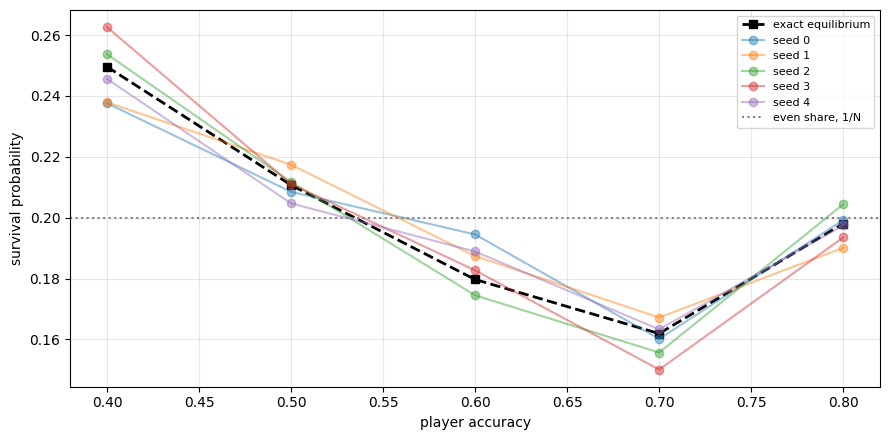

In [19]:
figure, axis = plt.subplots(figsize=(9, 4.5))
axis.plot(accuracies, [EXACT[a] for a in accuracies], "ks--",
          label="exact equilibrium", linewidth=2)
for seed in SEEDS:
    survival = survival_by_accuracy(seed_records[seed], accuracies)
    axis.plot(accuracies, [survival[a] for a in accuracies], "o-", alpha=0.45,
              label="seed " + str(seed))
axis.axhline(1.0 / N_PLAYERS, color="grey", linestyle=":",
             label="even share, 1/N")
axis.set_xlabel("player accuracy")
axis.set_ylabel("survival probability")
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Targeting — the U-shape, where it can finally appear

Step 5 established that this shape **cannot** exist at N=3, because there the equilibrium
is `shoot_strongest` and every rank fires at its stronger neighbour. At N=5 the exact
equilibrium does something neither `shoot_strongest` nor `coin_flip` does: **the extremes fire
at their stronger neighbour, and the middle ranks mostly fire at their weaker one.**

One fixed rule does share the shape. Under ranked seating the circle stays sorted as players
die, so Archetti's rule restricted to the two neighbours (shoot the strongest neighbour still
weaker than you; if both are stronger, the stronger one) always shoots left, and only the
weakest and the strongest have a stronger player on their left. That rule puts the middle ranks
at 0.2013 / 0.0930 / 0.2038 (folder 02 step 5), against the equilibrium's 0.3979 / 0.3107 /
0.3714, and it rises with contraction only as 2/5, 2/4, 2/3. The shape is necessary; the
magnitudes, and a near-certain shot at the stronger neighbour with three left, are what
separate the equilibrium from it.

In [20]:
print("%-6s %9s %9s %9s %9s %9s   %s"
      % ("seed", "0.4", "0.5", "0.6", "0.7", "0.8", "extremes vs middle"))

u_shaped = 0
for seed in SEEDS:
    cells = []
    values = {}
    for accuracy in accuracies:
        rate, stronger, decisions = targeting_rate(seed_records[seed], accuracy=accuracy)
        values[accuracy] = rate
        cells.append(format(rate, ".4f"))
    extremes = min(values[0.4], values[0.8])
    middle = max(values[0.5], values[0.6], values[0.7])
    if extremes > middle:
        u_shaped = u_shaped + 1
        mark = "extremes higher"
    else:
        mark = "not U-shaped"
    print("%-6d %9s %9s %9s %9s %9s   %s"
          % (seed, cells[0], cells[1], cells[2], cells[3], cells[4], mark))

print()
print("seeds where BOTH extremes exceed EVERY middle rank:", u_shaped, "of", len(SEEDS))
print()
print("The test is deliberately strict: the lowest of the two extremes must exceed the")
print("highest of the three middle ranks. A shape that only holds on average would not")
print("count.")

seed         0.4       0.5       0.6       0.7       0.8   extremes vs middle
0         1.0000    0.3705    0.3085    0.3678    1.0000   extremes higher
1         0.9998    0.3605    0.3127    0.3892    1.0000   extremes higher
2         1.0000    0.4066    0.3216    0.3662    0.9993   extremes higher
3         0.9998    0.4034    0.3325    0.3767    0.9992   extremes higher
4         1.0000    0.3627    0.2995    0.3715    1.0000   extremes higher

seeds where BOTH extremes exceed EVERY middle rank: 5 of 5

The test is deliberately strict: the lowest of the two extremes must exceed the
highest of the three middle ranks. A shape that only holds on average would not
count.


## Targeting by how many remain — three rows at last

At N=3 this table had exactly one row, because a two-player state is excluded and there
is nothing between three and two. At N=5 there are three rows, and the exact equilibrium
says they should differ: it fires at the stronger neighbour about 40% of the time while
five are alive, 50% at four, and 100% once three remain.

In [21]:
EQUILIBRIUM_BY_ALIVE = {5: 0.40, 4: 0.50, 3: 1.00}

print("%-6s %11s %11s %11s   %s" % ("seed", "5 alive", "4 alive", "3 alive", "rises?"))
rising = 0
for seed in SEEDS:
    rows_alive = targeting_by_alive(seed_records[seed])
    cells = []
    series = []
    for alive in [5, 4, 3]:
        if alive in rows_alive:
            cells.append(format(rows_alive[alive][0], ".4f"))
            series.append(rows_alive[alive][0])
        else:
            cells.append("no data")
            series.append(None)
    if None not in series and series[0] < series[1] < series[2]:
        rising = rising + 1
        mark = "yes"
    else:
        mark = "no"
    print("%-6d %11s %11s %11s   %s" % (seed, cells[0], cells[1], cells[2], mark))

print()
print("exact equilibrium:  %.2f        %.2f        %.2f"
      % (EQUILIBRIUM_BY_ALIVE[5], EQUILIBRIUM_BY_ALIVE[4], EQUILIBRIUM_BY_ALIVE[3]))
print()
print("seeds rising strictly as the circle contracts:", rising, "of", len(SEEDS))
print()
print("A rise alone does not show the agent reads how many remain. Under ranked seating")
print("always shooting left ignores the count and still rises, as 2/5, 2/4, 2/3, because")
print("only the weakest and the strongest have a stronger player on their left. What it")
print("cannot produce is the near-certain shot at the stronger neighbour with three left.")

seed       5 alive     4 alive     3 alive   rises?
0           0.4033      0.5035      0.9665   yes
1           0.4017      0.5078      0.9680   yes
2           0.4065      0.5191      0.9944   yes
3           0.3968      0.5262      0.9961   yes
4           0.4021      0.5043      0.9680   yes

exact equilibrium:  0.40        0.50        1.00

seeds rising strictly as the circle contracts: 5 of 5

A rise alone does not show the agent reads how many remain. Under ranked seating
always shooting left ignores the count and still rises, as 2/5, 2/4, 2/3, because
only the weakest and the strongest have a stronger player on their left. What it
cannot produce is the near-certain shot at the stronger neighbour with three left.


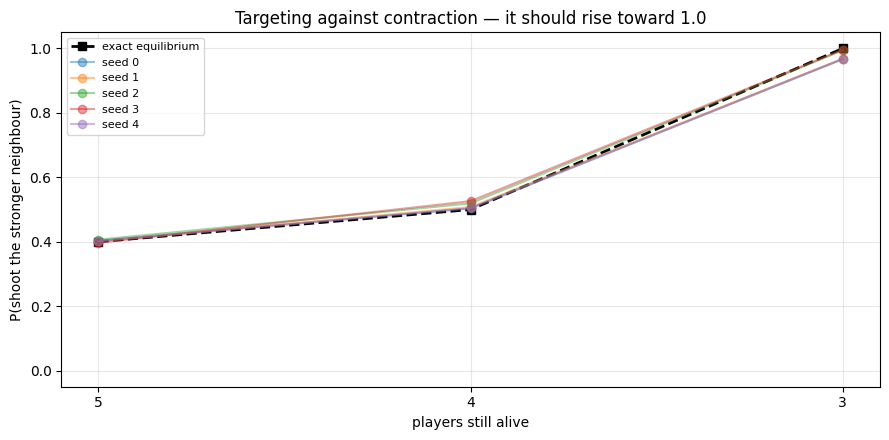

In [22]:
figure, axis = plt.subplots(figsize=(9, 4.5))
alive_axis = [5, 4, 3]
axis.plot(alive_axis, [EQUILIBRIUM_BY_ALIVE[a] for a in alive_axis], "ks--",
          label="exact equilibrium", linewidth=2)
for seed in SEEDS:
    rows_alive = targeting_by_alive(seed_records[seed])
    series = []
    for alive in alive_axis:
        if alive in rows_alive:
            series.append(rows_alive[alive][0])
        else:
            series.append(np.nan)
    axis.plot(alive_axis, series, "o-", alpha=0.45, label="seed " + str(seed))
axis.set_xlabel("players still alive")
axis.set_ylabel("P(shoot the stronger neighbour)")
axis.set_xticks(alive_axis)
axis.invert_xaxis()
axis.set_ylim(-0.05, 1.05)
axis.set_title("Targeting against contraction — it should rise toward 1.0")
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## What this step establishes

Assembled from the measurements above rather than written by hand, so it cannot drift
away from them.

In [23]:
print("1. equilibrium class      : every seed shooting?          ", all_shooting)
print("2. the gate               : %d of %d seeds reach %.2f      "
      % (seeds_passing, len(SEEDS), GATE_THRESHOLD),
      "-> " + ("PASS" if gate_passes else "FAIL"))
print("3. the non-monotone shape : minimum at 0.7 in %d of %d seeds"
      % (argmin_correct, len(SEEDS)))
print("4. the U-shape            : both extremes above every middle rank in %d of %d"
      % (u_shaped, len(SEEDS)))
print("5. survivor dependence    : targeting rises with contraction in %d of %d"
      % (rising, len(SEEDS)))
print()
print("Item 3 is the one no heuristic reproduces. Items 4 and 5 are shared in shape with")
print("Archetti's rule on the circle (always shoot left, under ranked seating); the size of")
print("the middle ranks and of the three-left rate is what separates the agent from it.")
print("The gate in item 2 is a")
print("necessary condition, not a sufficient one — shoot_strongest also passes a")
print("survival gate at N=3 while getting the targeting policy wrong from N=4 onward.")

1. equilibrium class      : every seed shooting?           True
2. the gate               : 4 of 5 seeds reach 0.95       -> PASS
3. the non-monotone shape : minimum at 0.7 in 5 of 5 seeds
4. the U-shape            : both extremes above every middle rank in 5 of 5
5. survivor dependence    : targeting rises with contraction in 5 of 5

Item 3 is the one no heuristic reproduces. Items 4 and 5 are shared in shape with
Archetti's rule on the circle (always shoot left, under ranked seating); the size of
the middle ranks and of the three-left rate is what separates the agent from it.
The gate in item 2 is a
necessary condition, not a sufficient one — shoot_strongest also passes a
survival gate at N=3 while getting the targeting policy wrong from N=4 onward.


## Reproducibility

Training five seeds twice would double the cost of the notebook for no extra
information, so what is repeated is the **measurement** — the part that produces every
number above — against a fixed policy.

**There are two random streams here, not one, and this is worth stating because getting
it wrong makes a working notebook look broken.** The environment has its own seed, which
decides who is drawn to act and whether a shot lands. But a trained policy also
*samples*: it converts its outputs into a distribution and draws from it, using torch's
global stream. Reseeding only the game leaves that second stream where the previous call
left it, so the two runs diverge and the check fails — while nothing is actually wrong.

Every earlier step's check happened to use a deterministic heuristic, so this never
surfaced. Here both streams are reset.

In [24]:
def measure_once():
    torch.manual_seed(7000)          # the policy samples, so its stream is reset too
    fixed_game = GruelEnv(n=N_PLAYERS, reward="terminal", seating="ranked", seed=9000)
    records = play_episodes(fixed_game, make_agent_policy(seed_model), 500)
    survival = survival_by_accuracy(records, accuracies)
    rate, stronger, decisions = targeting_rate(records)
    return (tuple(round(survival[a], 10) for a in accuracies),
            round(rate, 10), decisions)


first = measure_once()
second = measure_once()

print("first :", first)
print("second:", second)
print("identical:", first == second)

first : ((0.266, 0.204, 0.172, 0.176, 0.182), 0.6300555115, 2522)
second: ((0.266, 0.204, 0.172, 0.176, 0.182), 0.6300555115, 2522)
identical: True
